# 03 · Machine learning sobre la serie horaria

Este notebook prepara las variables de los modelos de machine learning, explica cómo se evitan las fugas de información, valida Ridge, SVR, Random Forest y XGBoost con particiones temporales y ajusta los hiperparámetros del mejor.

Los modelos se entrenan en la serie horaria porque es más rica: el perfil del día (picos de entrada y salida del trabajo) es la mayor fuente de variación. Para compararlos con los estadísticos, sus predicciones horarias se suman por día (notebook 04).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from bike_sharing import RANDOM_STATE, datos
from bike_sharing.datos import RAIZ, INICIO_PRUEBA, FIN_PRUEBA

RESULTADOS = RAIZ / "results"
FIGURAS = RESULTADOS / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (12, 4.5), "figure.dpi": 100, "axes.titleweight": "bold"})
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
np.random.seed(RANDOM_STATE)

from sklearn.model_selection import TimeSeriesSplit
from bike_sharing import escenarios, ml, variables

h = datos.serie_horaria()
cv = json.loads((RESULTADOS / "validacion_cruzada.json").read_text(encoding="utf-8"))
grupos = json.loads((RESULTADOS / "por_grupo.json").read_text(encoding="utf-8"))
print(f"Rejilla horaria: {h.index[0]} a {h.index[-1]} · {len(h):,} horas ({h['imputada'].sum()} imputadas con demanda 0)")

Rejilla horaria: 2011-01-01 00:00:00 a 2012-12-31 23:00:00 · 17,544 horas (165 imputadas con demanda 0)


## 1. Variables

### 1.1 Calendario y clima

Para cada hora se construyen variables de calendario (hora, día de la semana, mes, año, estación, festivo, laboral, fin de semana, día del año) y su codificación cíclica: la hora 23 y la hora 0 son vecinas, y con seno y coseno un modelo lineal lo puede ver. El clima de la hora (`temp_c`, `hum_pct`, `viento_kmh`, `weathersit`) se supone conocido de antemano en todos los escenarios. Es un supuesto optimista, porque en la práctica se usaría un pronóstico del tiempo, pero es el mismo para todos los modelos.

### 1.2 Rezagos y estadísticas móviles según el escenario

La información que puede usar un modelo depende de **cuándo** se hace el pronóstico. Por eso cada escenario tiene su propio conjunto de variables dinámicas:

| Escenario | Se conoce la demanda hasta | Rezagos | Media y desviación móviles |
| --- | --- | --- | --- |
| A. Hora siguiente | la hora anterior (t − 1) | 1, 24 y 168 h | ventanas de 24 y 168 h que terminan en t − 1 |
| B. Día siguiente | las 23:00 del día anterior | 24 y 168 h | ventanas de 24 y 168 h calculadas al cierre del día anterior |
| C. Mes completo | las 23:00 del 2012-12-01 | las de A, con las predicciones propias en lugar de los datos reales | ídem |

En A, la ventana móvil se calcula sobre `cnt.shift(1)`, así nunca incluye la hora que se quiere predecir. En B, la hora objetivo está entre 1 y 24 horas después del cierre, de modo que el rezago de 24 h siempre es un dato ya conocido, y las ventanas móviles se congelan al cierre y se repiten en las 24 horas del día siguiente.

In [2]:
Xa, Xb = variables.variables_a(h), variables.variables_b(h)
t = pd.Timestamp("2012-12-05 17:00")
dinamicas_a = variables.columnas_dinamicas_a()
dinamicas_b = [c for c in Xb.columns if c.startswith(("lag", "media", "desv"))]
print("Hora objetivo:", t, "· demanda real:", h.loc[t, "cnt"])
pd.concat({"A": Xa.loc[t, dinamicas_a], "B": Xb.loc[t, dinamicas_b]}).to_frame("valor")

Hora objetivo: 2012-12-05 17:00:00 · demanda real: 605


valor
A lag_1h            377.00
  lag_24h           743.00
  lag_168h          563.00
  media_24h         259.50
  desv_24h          230.34
  media_168h        234.00
  desv_168h         193.50
B lag_24h           743.00
  lag_168h          563.00
  media_24h_cierre  275.25
  desv_24h_cierre   228.26
  media_168h_cierre 231.73
  desv_168h_cierre  192.39

Las pruebas de `tests/test_variables.py` verifican que no hay fuga: se reemplaza por ruido toda la demanda posterior al instante permitido (desde la hora t en A, desde las 00:00 del día objetivo en B) y se comprueba que las variables no cambian. Una prueba de control altera el día anterior y verifica que en B sí cambian.

`casual` y `registered` nunca entran como variables: suman exactamente `cnt`.

## 2. Validación temporal

Se usa `TimeSeriesSplit` con 5 particiones sobre el entrenamiento: cada partición entrena con todo el pasado y valida en el bloque siguiente.

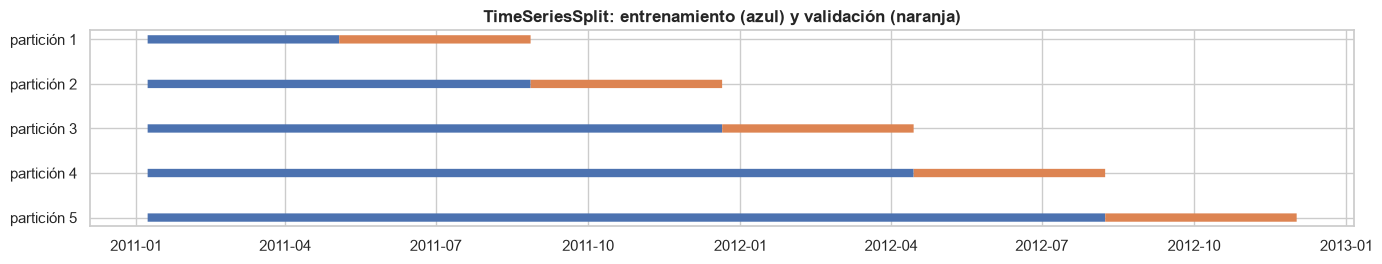

In [3]:
X_tr, y_tr, _, _ = escenarios.conjunto_ml(Xa, h["cnt"])
fig, ax = plt.subplots(figsize=(14, 2.8))
for i, (tr, va) in enumerate(TimeSeriesSplit(n_splits=5).split(X_tr)):
    ax.plot(X_tr.index[tr], np.full(len(tr), i), color="C0", lw=6, solid_capstyle="butt")
    ax.plot(X_tr.index[va], np.full(len(va), i), color="C1", lw=6, solid_capstyle="butt")
ax.set(yticks=range(5), yticklabels=[f"partición {i + 1}" for i in range(5)], title="TimeSeriesSplit: entrenamiento (azul) y validación (naranja)")
ax.invert_yaxis(); plt.tight_layout(); plt.show()

**Por qué no un `train_test_split` aleatorio.** Si las horas se repartieran al azar, el entrenamiento tendría horas posteriores a las de validación, y con un rezago de 1 h el modelo vería prácticamente el dato que debe predecir (la hora siguiente y la anterior a cada hora de validación estarían en el entrenamiento). El error de validación saldría optimista y no representaría el uso real, donde siempre se pronostica el futuro con el pasado. Las particiones temporales respetan ese orden y, además, muestran cómo varía el error entre épocas del año.

## 3. Comparación de modelos

- **Ridge:** regresión lineal con regularización L2; variables estandarizadas.
- **SVR:** regresión de vectores de soporte con núcleo RBF; variables y objetivo estandarizados.
- **Random Forest:** 200 árboles.
- **XGBoost:** 300 árboles con *boosting* de gradiente.

In [4]:
def tabla_cv(esc):
    t = pd.DataFrame(cv[esc]["metricas"]).T
    return t[["MAE_media", "MAE_desv", "RMSE_media", "WAPE_media", "WAPE_desv"]]

print("Escenario A · hora siguiente")
display(tabla_cv("A"))
print("Escenario B · día siguiente")
display(tabla_cv("B"))

Escenario A · hora siguiente


,MAE_media,MAE_desv,RMSE_media,WAPE_media,WAPE_desv
XGBoost ajustado,30.52,4.49,49.13,14.98,2.90
XGBoost,32.96,5.15,53.12,16.18,3.13
Random Forest,33.95,5.49,55.65,16.59,2.76
Ridge,47.56,6.68,70.24,23.14,2.67
SVR,57.04,19.79,84.23,28.87,12.76


Escenario B · día siguiente


,MAE_media,MAE_desv,RMSE_media,WAPE_media,WAPE_desv
XGBoost ajustado,41.94,4.40,66.01,20.73,4.42
XGBoost,43.13,4.20,68.25,21.44,5.14
Random Forest,46.30,4.86,73.52,22.68,3.32
Ridge,59.86,12.25,87.20,29.45,7.55
SVR,63.41,17.51,93.01,31.99,12.23


En los dos escenarios los modelos de árboles superan con amplitud a Ridge y SVR, y XGBoost es el mejor. Ridge solo puede combinar las variables de forma lineal y no captura que el efecto de la hora depende del tipo de día. El SVR tiene además la mayor dispersión entre particiones (desviación del MAE de 18–20, frente a 4–5 de los árboles): en las primeras, entrenadas con pocos meses de 2011, subestima la demanda, porque un núcleo RBF no extrapola el crecimiento del sistema más allá de los niveles que ya vio. Con todo el entrenamiento ese problema se reduce, y en la prueba de diciembre el SVR rinde mucho mejor de lo que anticipa esta tabla (notebook 04).

El error de B es mayor que el de A en todos los modelos: sin la demanda de la hora anterior, el modelo debe reconstruir el nivel del día a partir del calendario, el clima y la historia hasta ayer.

Las particiones validan en épocas distintas (de mayo a agosto de 2011, de agosto a diciembre de 2011, de diciembre de 2011 a abril de 2012, de abril a agosto de 2012 y de agosto a diciembre de 2012), con volúmenes de demanda distintos; por eso se reporta también la desviación entre ellas.

## 4. Ajuste de hiperparámetros

Sobre el mejor modelo de cada escenario se hace una búsqueda aleatoria de 20 combinaciones (`RandomizedSearchCV`) con la misma validación temporal y el MAE como criterio.

In [5]:
pd.DataFrame({esc: {"modelo": cv[esc]["mejor_base"], "MAE base": cv[esc]["metricas"][cv[esc]["mejor_base"]]["MAE_media"],
                    "MAE ajustado": cv[esc]["MAE_busqueda"], **{k: v for k, v in cv[esc]["hiperparametros"].items()}}
              for esc in ("A", "B")})

,A,B
modelo,XGBoost,XGBoost
MAE base,32.96,43.13
MAE ajustado,30.53,41.94
subsample,0.70,0.70
n_estimators,800,800
min_child_weight,5,5
max_depth,6,6
learning_rate,0.02,0.02
colsample_bytree,0.80,0.80


La búsqueda llega a la misma combinación en los dos escenarios: más árboles (800) con una tasa de aprendizaje menor (0,02) y submuestreo de filas y columnas, una configuración más regularizada que la base. La mejora en MAE es de un 7 % en A y un 3 % en B. El modelo ajustado de cada escenario entra en las tablas de prueba como «XGBoost ajustado», junto con los cuatro modelos base.

## 5. Importancia de las variables

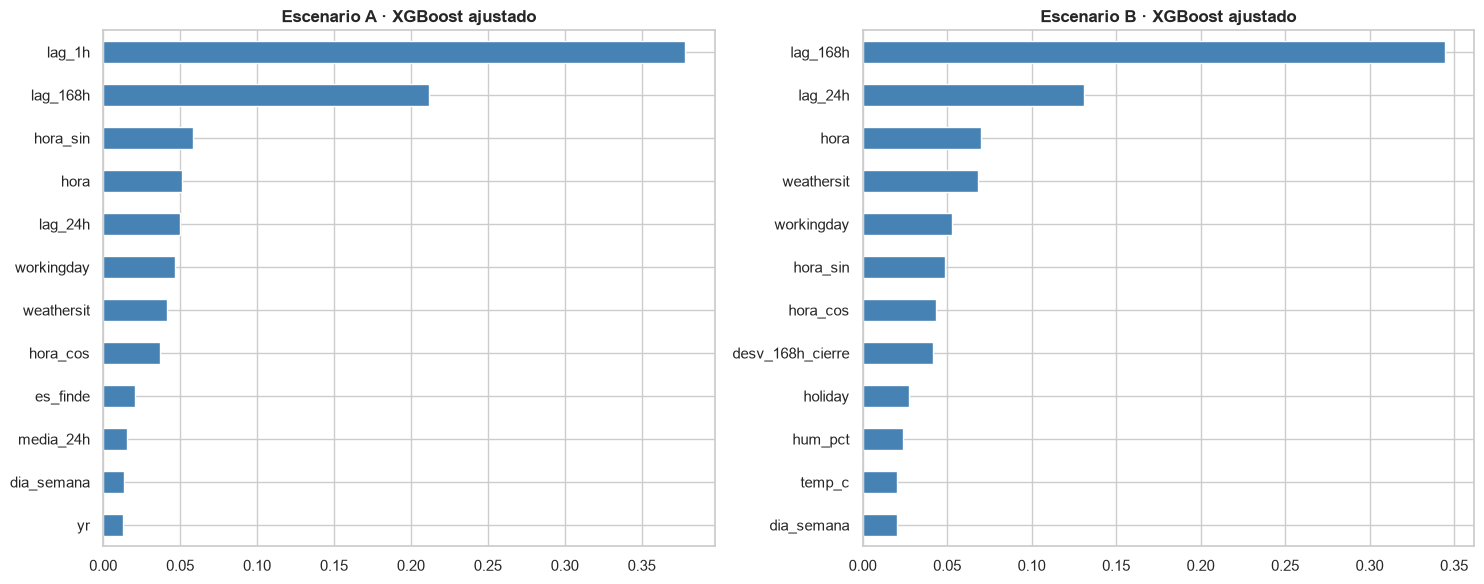

In [6]:
X_tr_b, y_tr_b, _, _ = escenarios.conjunto_ml(Xb, h["cnt"])
fig, ejes = plt.subplots(1, 2, figsize=(15, 6))
for ax, esc, (X, yy) in zip(ejes, ("A", "B"), ((X_tr, y_tr), (X_tr_b, y_tr_b))):
    modelo = ml.modelos_base()[cv[esc]["mejor_base"]].set_params(**cv[esc]["hiperparametros"]).fit(X, yy)
    imp = pd.Series(modelo.feature_importances_, index=X.columns).sort_values().tail(12)
    imp.plot.barh(ax=ax, color="steelblue"); ax.set_title(f"Escenario {esc} · {cv[esc]['mejor_base']} ajustado")
plt.tight_layout(); plt.show()

En el escenario A domina la demanda de la hora anterior (`lag_1h`), seguida de la misma hora de la semana pasada (`lag_168h`): la primera da el nivel inmediato y la segunda, el perfil del mismo día de la semana. En el B, sin la hora anterior, el peso pasa a la misma hora de la semana pasada y de ayer, y después a la hora del día, la situación del tiempo y el tipo de día: el modelo reconstruye el perfil horario a partir de la historia y lo ajusta con el calendario y el clima. La temperatura pesa poco en los dos, porque los rezagos ya traen el nivel de la época del año; la situación del tiempo, en cambio, cambia de un día a otro y los rezagos no la anticipan.

## 6. Error según tipo de día y estación

Las predicciones fuera de partición de la validación cubren de mayo de 2011 a noviembre de 2012, así que permiten ver el error en todas las estaciones (la prueba solo cubre diciembre).

In [7]:
def por_grupo(clave, modelo):
    t = pd.DataFrame(grupos[clave][modelo]).T[["MAE", "WAPE", "n"]]
    return t

filas = []
for esc in ("A", "B"):
    m = f"{cv[esc]['mejor_base']} ajustado"
    for g in ("estacion", "tipo_de_dia"):
        t = por_grupo(f"validacion_{esc}_{g}", m)
        t.index = pd.MultiIndex.from_product([[f"{esc} · {m}"], t.index])
        filas.append(t)
tabla_grupos = pd.concat(filas)
tabla_grupos

MAE  WAPE        n
A · XGBoost ajustado primavera               36.55 15.56 3,368.00
                     verano                  32.79 13.94 4,512.00
                     otoño                   26.03 13.36 3,816.00
                     invierno                24.40 16.49 2,184.00
                     laboral                 29.97 14.06 9,512.00
                     fin de semana o festivo 31.73 15.54 4,368.00
B · XGBoost ajustado primavera               48.17 20.51 3,368.00
                     verano                  41.87 17.80 4,512.00
                     otoño                   38.71 19.86 3,816.00
                     invierno                38.11 25.76 2,184.00
                     laboral                 39.60 18.58 9,512.00
                     fin de semana o festivo 47.02 23.03 4,368.00

El WAPE es mayor en invierno, cuando la demanda es baja y cualquier error pesa más en relación con el total, y en fines de semana y festivos, cuando el uso depende más del tiempo y de los usuarios casuales, menos predecibles que los viajes al trabajo. El MAE se comporta al revés en las estaciones (es mayor en primavera y verano, con más volumen, y menor en invierno), por eso se miran las dos métricas.

## Resumen

- Variables construidas por escenario según la información disponible en el momento del pronóstico, con pruebas de no fuga.
- Validación con `TimeSeriesSplit` de 5 particiones; los modelos de árboles son los mejores en los dos escenarios.
- Hiperparámetros ajustados sobre el mejor modelo de cada escenario.
- La comparación en la prueba, con los modelos estadísticos y las referencias ingenuas, está en el notebook 04.